# Frozen CLIP + configurable MLP probe on NWPU-RESISC45

1. Load the image dataset and create reproducible train/validation/test splits.
2. Extract **normalized CLIP embeddings** with the image encoder **frozen**.
3. Train a configurable classifier (linear baseline or MLP) on the embeddings.
4. Select the best checkpoint by validation accuracy; evaluate on the test split once.

**Note:** This notebook preserves your original 16% train / 4% validation / 80% test split. Adjust the split ratios in the dataset cell if that was not intended.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q open_clip_torch
import contextlib
from pathlib import Path
from types import SimpleNamespace

import open_clip
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from tqdm.auto import tqdm

In [3]:
# CLIP's image normalization statistics (RGB).
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def preprocess(images, size, device):
    """Resize and normalize ImageFolder/ToTensor batches already in [0, 1]."""
    x = images.to(device, non_blocking=True)
    x = F.interpolate(x, size=size, mode="bicubic", align_corners=False, antialias=True)
    x = x.clamp(0, 1)
    mean = x.new_tensor(CLIP_MEAN).view(1, 3, 1, 1)
    std = x.new_tensor(CLIP_STD).view(1, 3, 1, 1)
    return (x - mean) / std


@torch.no_grad()
def extract_features(model, dataset, args, device):
    """Run frozen CLIP image encoder over dataset -> (features, labels) on CPU."""
    loader = DataLoader(
        dataset,
        batch_size=args.extract_batch_size,
        shuffle=False,
        num_workers=args.workers,
        pin_memory=device.type == "cuda",
    )
    size = model.visual.image_size
    size = (size, size) if isinstance(size, int) else tuple(size)
    features, labels = [], []
    model.eval()
    for images, batch_labels in tqdm(loader, desc="Extracting CLIP features", leave=False):
        x = preprocess(images, size, device)
        with (torch.autocast("cuda", dtype=torch.float16)
              if device.type == "cuda" else contextlib.nullcontext()):
            embeddings = model.encode_image(x)
        features.append(F.normalize(embeddings.float(), dim=-1).cpu())
        labels.append(torch.as_tensor(batch_labels).long().cpu())
    return torch.cat(features), torch.cat(labels)


class MLPProbe(nn.Module):
    """Trainable linear or nonlinear probe; CLIP is not part of this module."""

    def __init__(self, in_dim, num_classes, mean, std, hidden_dims=(256, 128), dropout=0.3):
        super().__init__()
        self.register_buffer("mean", mean)
        self.register_buffer("std", std)

        layers = []
        prev_dim = in_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, num_classes))
        self.fc = nn.Sequential(*layers)

    def forward(self, x):
        return self.fc((x - self.mean) / self.std)


@torch.no_grad()
def accuracy(clf, x, y, bs=4096):
    clf.eval()  # turn off dropout for evaluation
    correct = sum(
        (clf(x[i:i + bs]).argmax(dim=1) == y[i:i + bs]).sum().item()
        for i in range(0, len(x), bs)
    )
    return correct / len(x)

In [10]:
# for getting the data into colab runtime
!cp /content/drive/MyDrive/Gervigreind_lokaverkefni//NWPU-RESISC45.zip /content/
!unzip -q /content/NWPU-RESISC45.zip -d /content/data

In [11]:
# Location of unzipped NWPU-RESISC45 image class folders
ROOT = Path("data/NWPU-RESISC45")
if not ROOT.is_dir():
    raise FileNotFoundError(f"Dataset folder not found: {ROOT.resolve()}")

dataset = ImageFolder(root=ROOT, transform=ToTensor())
print("Dataset location:", ROOT.resolve())
print("Images:", len(dataset))
print("Classes:", len(dataset.classes))
print(dataset.classes)

Dataset location: /content/data/NWPU-RESISC45
Images: 31500
Classes: 45
['airplane', 'airport', 'baseball_diamond', 'basketball_court', 'beach', 'bridge', 'chaparral', 'church', 'circular_farmland', 'cloud', 'commercial_area', 'dense_residential', 'desert', 'forest', 'freeway', 'golf_course', 'ground_track_field', 'harbor', 'industrial_area', 'intersection', 'island', 'lake', 'meadow', 'medium_residential', 'mobile_home_park', 'mountain', 'overpass', 'palace', 'parking_lot', 'railway', 'railway_station', 'rectangular_farmland', 'river', 'roundabout', 'runway', 'sea_ice', 'ship', 'snowberg', 'sparse_residential', 'stadium', 'storage_tank', 'tennis_court', 'terrace', 'thermal_power_station', 'wetland']


In [12]:
# Reproducible data split. Preserving original: 16% train, 4% val, 80% test.
dataset_size = len(dataset)
test_size = int(0.80 * dataset_size)
train_size = int(0.16 * dataset_size)
val_size = dataset_size - train_size - test_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42),
)

# No need to concatenate all images into RAM; extract_features creates its own DataLoader.
print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Training dataset size: 5040
Validation dataset size: 1260
Test dataset size: 25200


In [13]:
args = SimpleNamespace(
    model="ViT-B-32",
    pretrained="openai",
    cache_dir=None,
    extract_batch_size=64,
    workers=4,
    epochs=100,
    batch_size=64,
    lr=1e-3,
    weight_decay=1e-4,
    seed=42,
    hidden_dims=(256, 128),  # () = linear, (256,) = 1 hidden, (256,128) = 2
    dropout=0.3,
    out="clip_mlp_probe_resisc45.pt",
)

torch.manual_seed(args.seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(args.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

clip_model, _, _ = open_clip.create_model_and_transforms(
    args.model, pretrained=args.pretrained, cache_dir=args.cache_dir
)
clip_model = clip_model.to(device).eval().requires_grad_(False)

x_tr, y_tr = extract_features(clip_model, train_dataset, args, device)
x_va, y_va = extract_features(clip_model, val_dataset, args, device)
x_te, y_te = extract_features(clip_model, test_dataset, args, device)

# Features/labels to training device; discard CLIP model to free GPU memory.
del clip_model
if device.type == "cuda":
    torch.cuda.empty_cache()
x_tr, y_tr, x_va, y_va, x_te, y_te = (
    t.to(device) for t in (x_tr, y_tr, x_va, y_va, x_te, y_te)
)
classes = dataset.classes

Device: cuda


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creatio

Extracting CLIP features:   0%|          | 0/79 [00:00<?, ?it/s]

Extracting CLIP features:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting CLIP features:   0%|          | 0/394 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c87a3fe6fc0><function _MultiProcessingDataLoaderIter.__del__ at 0x7c87a3fe6fc0>Exception ignored in: 

<function _MultiProcessingDataLoaderIter.__del__ at 0x7c87a3fe6fc0>Traceback (most recent call last):
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
        self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in: 
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7c87a3fe6fc0>self._shutdown_workers()  File "/usr/local/lib/p

In [14]:
# Train only the MLP / linear head (CLIP image encoder remains frozen).
clf = MLPProbe(
    in_dim=x_tr.shape[1],
    num_classes=len(classes),
    mean=x_tr.mean(dim=0),
    std=x_tr.std(dim=0) + 1e-6,
    hidden_dims=args.hidden_dims,
    dropout=args.dropout,
).to(device)

opt = torch.optim.AdamW(clf.parameters(), lr=args.lr, weight_decay=args.weight_decay)
steps_per_epoch = (len(x_tr) + args.batch_size - 1) // args.batch_size
sched = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt, T_max=args.epochs * steps_per_epoch
)
best_val, best_state = -1.0, None

for epoch in range(1, args.epochs + 1):
    clf.train()
    perm = torch.randperm(len(x_tr), device=device)
    running_loss = 0.0

    for i in range(0, len(x_tr), args.batch_size):
        idx = perm[i:i + args.batch_size]
        logits = clf(x_tr[idx])
        loss = F.cross_entropy(logits, y_tr[idx])

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        running_loss += loss.item() * len(idx)

    train_loss = running_loss / len(x_tr)
    val_acc = accuracy(clf, x_va, y_va)
    if val_acc > best_val:
        best_val = val_acc
        best_state = {k: v.detach().clone() for k, v in clf.state_dict().items()}

    if epoch == 1 or epoch % 10 == 0 or epoch == args.epochs:
        print(f"epoch {epoch:3d} | train loss {train_loss:.4f} | val acc {val_acc:.4f}")

clf.load_state_dict(best_state)
test_acc = accuracy(clf, x_te, y_te)
print(f"\nBest val acc: {best_val:.4f} | Test acc: {test_acc:.4f}")

torch.save(
    {
        "state_dict": clf.state_dict(),
        "classes": classes,
        "clip_model": args.model,
        "pretrained": args.pretrained,
        "in_dim": x_tr.shape[1],
        "hidden_dims": tuple(args.hidden_dims),
        "dropout": args.dropout,
        "val_acc": best_val,
        "test_acc": test_acc,
    },
    args.out,
)
print(f"Saved classifier to {args.out}")

epoch   1 | train loss 2.0628 | val acc 0.8024
epoch  10 | train loss 0.1721 | val acc 0.8651
epoch  20 | train loss 0.0753 | val acc 0.8643
epoch  30 | train loss 0.0470 | val acc 0.8762
epoch  40 | train loss 0.0342 | val acc 0.8817
epoch  50 | train loss 0.0231 | val acc 0.8643
epoch  60 | train loss 0.0205 | val acc 0.8833
epoch  70 | train loss 0.0100 | val acc 0.8786
epoch  80 | train loss 0.0074 | val acc 0.8770
epoch  90 | train loss 0.0072 | val acc 0.8778
epoch 100 | train loss 0.0084 | val acc 0.8778

Best val acc: 0.8833 | Test acc: 0.8895
Saved classifier to clip_mlp_probe_resisc45.pt


## Confusion matrix (test split)

Uses the best-validation checkpoint already loaded in `clf`, and the test features `x_te` / labels `y_te`. Rows are true classes, columns are predicted classes.

Test accuracy from confusion matrix: 0.8895


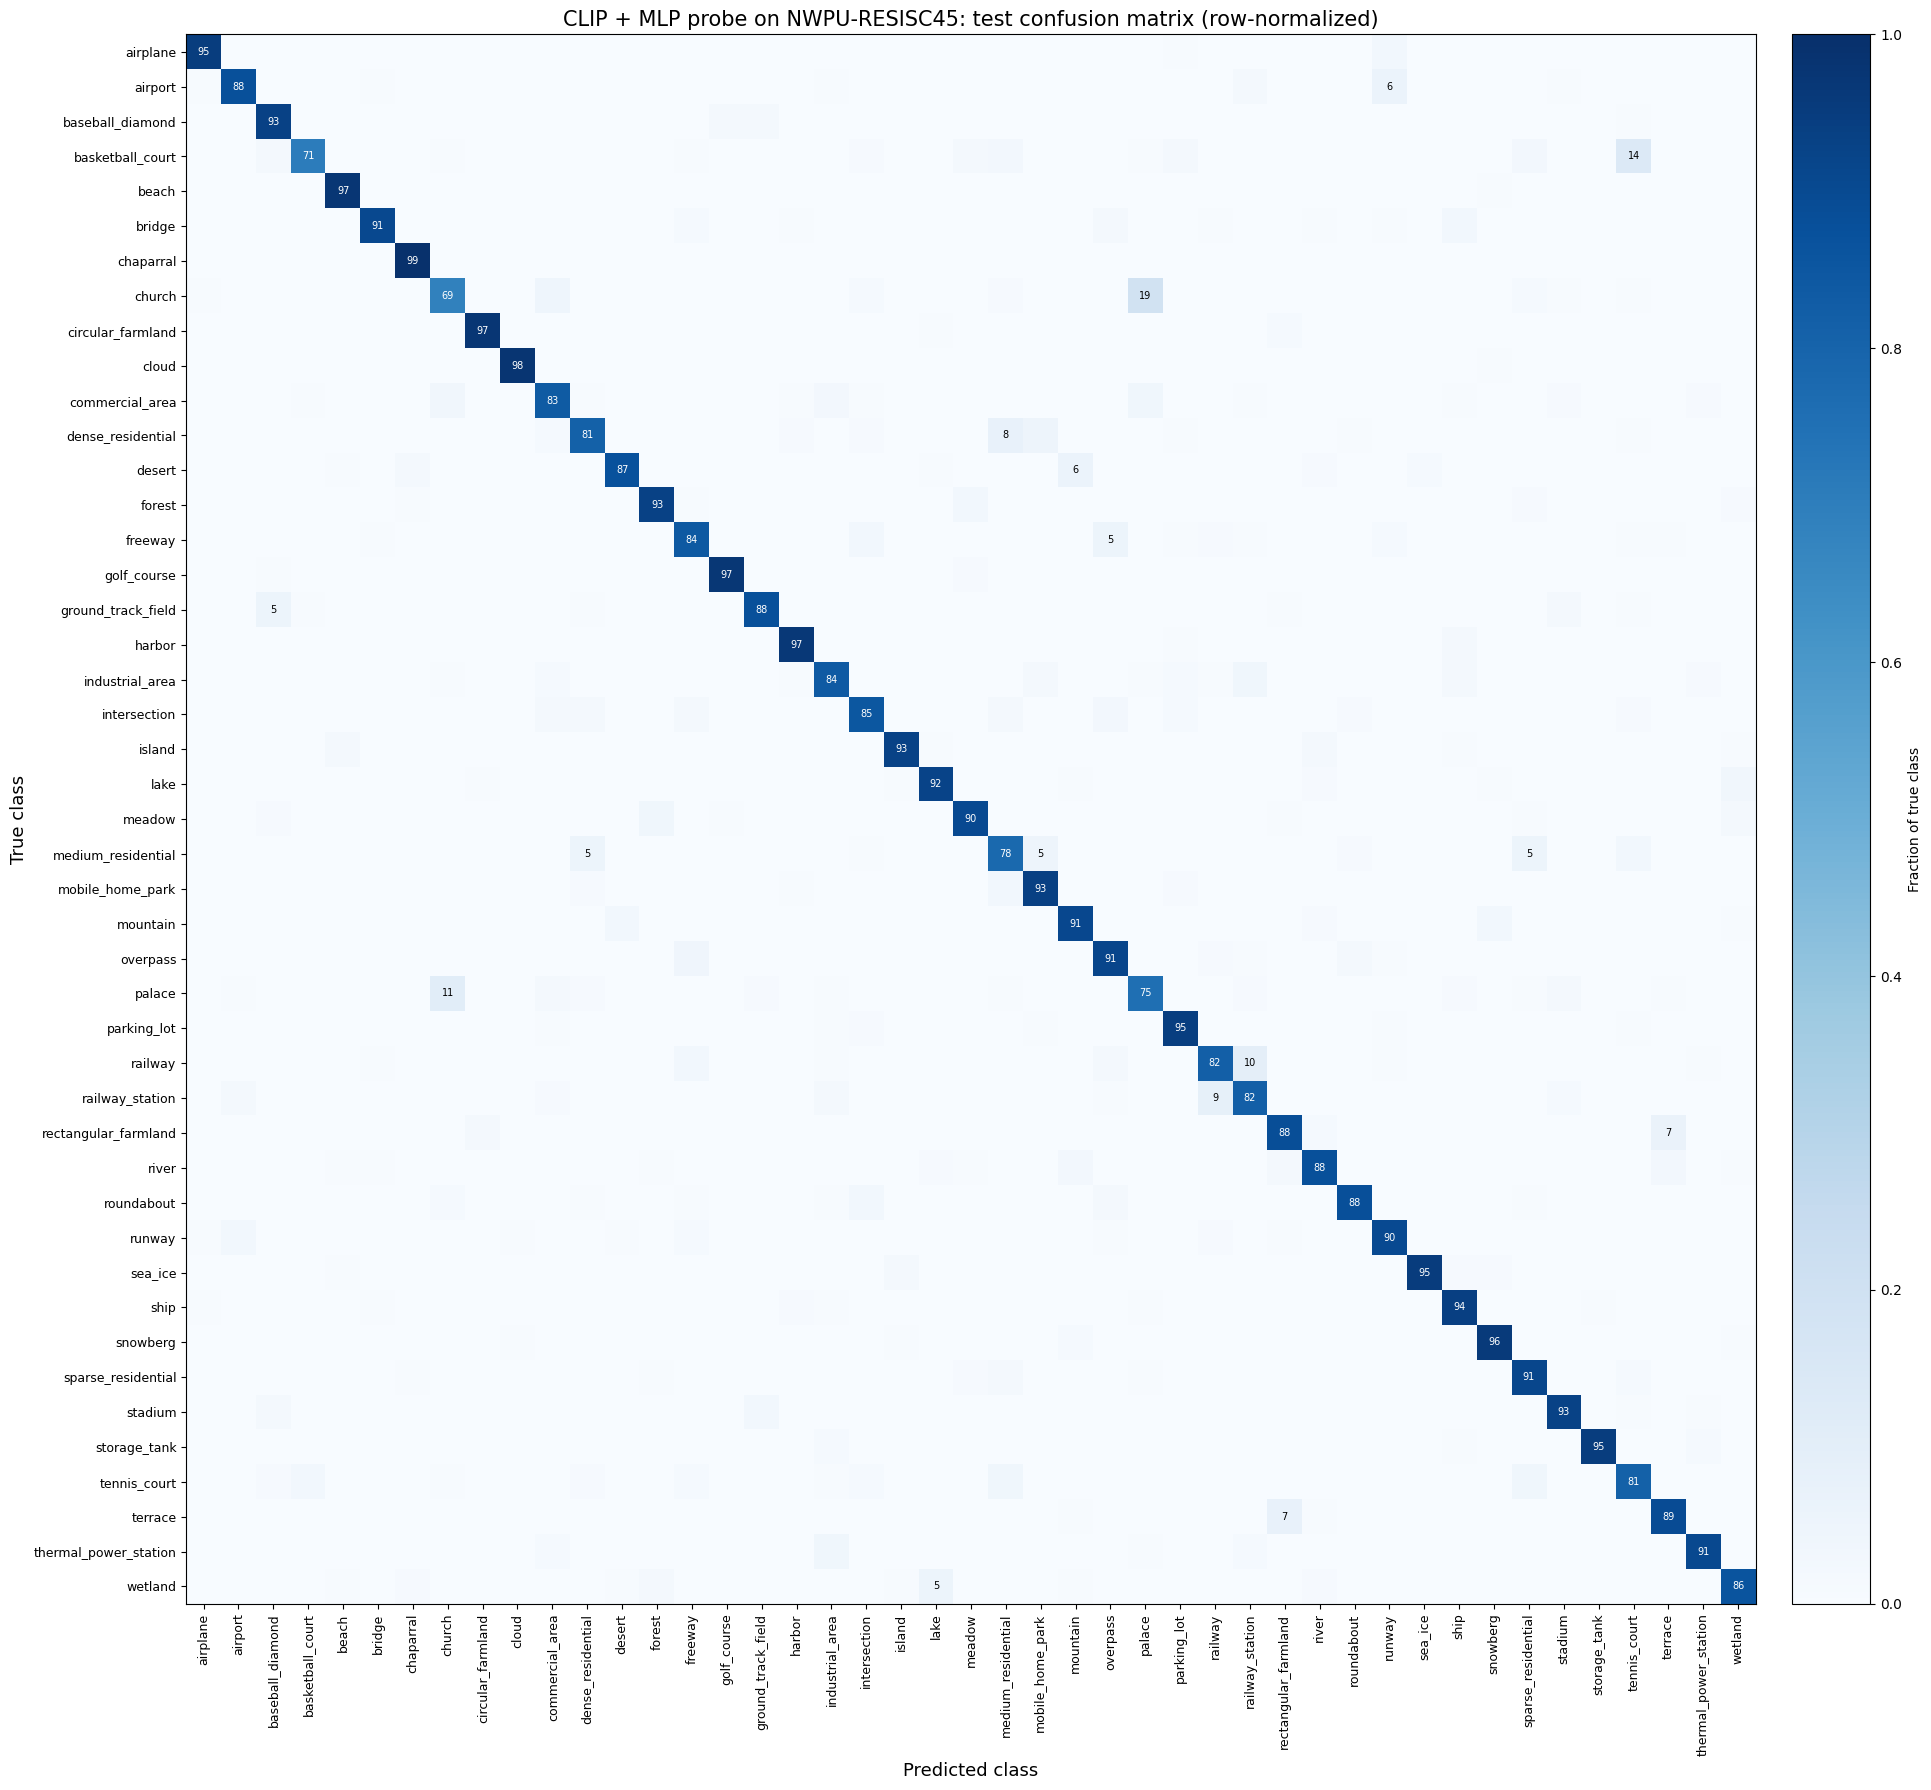


Worst 10 classes (recall):
  church                 0.686
  basketball_court       0.706
  palace                 0.755
  medium_residential     0.778
  tennis_court           0.810
  dense_residential      0.812
  railway_station        0.817
  railway                0.819
  commercial_area        0.832
  industrial_area        0.836

Top 10 confusions (true -> predicted):
  church               -> palace                108 images
  basketball_court     -> tennis_court           78 images
  palace               -> church                 58 images
  railway              -> railway_station        54 images
  railway_station      -> railway                48 images
  dense_residential    -> medium_residential     44 images
  terrace              -> rectangular_farmland   39 images
  rectangular_farmland -> terrace                36 images
  desert               -> mountain               35 images
  airport              -> runway                 34 images


In [15]:
# Confusion matrix on the test split, using the best-validation checkpoint now loaded in `clf`.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1) Predictions on the test set
clf.eval()
with torch.no_grad():
    y_pred = torch.cat([
        clf(x_te[i:i + 4096]).argmax(dim=1) for i in range(0, len(x_te), 4096)
    ]).cpu().numpy()
y_true = y_te.cpu().numpy()

labels = np.arange(len(classes))
cm = confusion_matrix(y_true, y_pred, labels=labels)             # raw counts
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)      # each row sums to 1 (per-class recall)
print(f"Test accuracy from confusion matrix: {np.trace(cm) / cm.sum():.4f}")

# 2) Heatmap (row-normalized; cells >= 5% are annotated with the percentage)
fig, ax = plt.subplots(figsize=(20, 18))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(labels)
ax.set_yticks(labels)
ax.set_xticklabels(classes, rotation=90, fontsize=9)
ax.set_yticklabels(classes, fontsize=9)
ax.set_xlabel("Predicted class", fontsize=13)
ax.set_ylabel("True class", fontsize=13)
ax.set_title("CLIP + MLP probe on NWPU-RESISC45: test confusion matrix (row-normalized)", fontsize=15)

for i in range(len(classes)):
    for j in range(len(classes)):
        if cm_norm[i, j] >= 0.05:
            ax.text(j, i, f"{cm_norm[i, j] * 100:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cm_norm[i, j] > 0.5 else "black")

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="Fraction of true class")
plt.tight_layout()
plt.savefig("confusion_matrix_resisc45.png", dpi=200, bbox_inches="tight")
plt.show()

# 3) Where the errors are
per_class_acc = np.diag(cm_norm)
print("\nWorst 10 classes (recall):")
for k in np.argsort(per_class_acc)[:10]:
    print(f"  {classes[k]:<22s} {per_class_acc[k]:.3f}")

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
print("\nTop 10 confusions (true -> predicted):")
for flat in np.argsort(off_diag, axis=None)[::-1][:10]:
    t, p = np.unravel_index(flat, off_diag.shape)
    print(f"  {classes[t]:<20s} -> {classes[p]:<20s} {off_diag[t, p]:4d} images")